In [1]:
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping

from cnn_project.utils.data_loader import load_datasets
from cnn_project.constants import TRAIN_DATA_C, TEST_DATA_C

In [2]:
(train, val, test, classes) = load_datasets(train_dir=TRAIN_DATA_C, test_dir=TEST_DATA_C)

Found 5000 files belonging to 4 classes.
Using 4000 files for training.
Found 5000 files belonging to 4 classes.
Using 1000 files for validation.
Found 1000 files belonging to 4 classes.


In [3]:
callback = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

model = models.Sequential([
    layers.Input(shape=(150, 150, 1)),
    layers.Rescaling(1.0 / 255.0),
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.1),

    layers.Conv2D(filters=32, kernel_size=(3,3), activation="relu", padding="same"),
    # layers.BatchNormalization(),
    layers.MaxPooling2D(),

    layers.Conv2D(filters=64, kernel_size=(3,3), activation="relu", padding="same"),
    # layers.BatchNormalization(),
    layers.MaxPooling2D(),

    layers.Conv2D(filters=128, kernel_size=(3,3), activation="relu", padding="same"),
    # layers.BatchNormalization(),

    layers.Conv2D(filters=256, kernel_size=(3,3), activation="relu", padding="same"),
    # layers.BatchNormalization(),

    layers.GlobalAveragePooling2D(),
    layers.Dropout(rate=0.3),
    layers.Dense(len(classes))

])

model.compile(
    optimizer="adam",
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=["accuracy"]
)

history = model.fit(
    train,
    epochs=20,
    validation_data=val,
    callbacks=[callback]
)

Epoch 1/20


/Users/marekpuskas/Documents/CNN/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


125/125 ━━━━━━━━━━━━━━━━━━━━ 39s 310ms/step - accuracy: 0.4223 - loss: 1.2549 - val_accuracy: 0.4290 - val_loss: 1.2438
Epoch 2/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 39s 314ms/step - accuracy: 0.5857 - loss: 1.0302 - val_accuracy: 0.6330 - val_loss: 0.8608
Epoch 3/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 41s 332ms/step - accuracy: 0.6505 - loss: 0.8962 - val_accuracy: 0.7080 - val_loss: 0.7785
Epoch 4/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 41s 330ms/step - accuracy: 0.6705 - loss: 0.8572 - val_accuracy: 0.6470 - val_loss: 0.8222
Epoch 5/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 41s 331ms/step - accuracy: 0.6775 - loss: 0.8328 - val_accuracy: 0.7370 - val_loss: 0.7622
Epoch 6/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 43s 342ms/step - accuracy: 0.6900 - loss: 0.8017 - val_accuracy: 0.7270 - val_loss: 0.6972
Epoch 7/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 45s 359ms/step - accuracy: 0.6995 - loss: 0.7875 - val_accuracy: 0.7360 - val_loss: 0.6863
Epoch 8/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 43s 341ms/step - accuracy: 0.7113 - loss: 0.7550 - val

In [ ]:
import numpy as np

# 1. Is the model also bad on TRAIN data in inference mode?
model.evaluate(train)
model.evaluate(val)

# 2. Is it predicting a single class on val?
preds = model.predict(val).argmax(axis=1)
print(np.bincount(preds, minlength=len(classes)))

125/125 ━━━━━━━━━━━━━━━━━━━━ 11s 92ms/step - accuracy: 0.4210 - loss: 1.7729
32/32 ━━━━━━━━━━━━━━━━━━━━ 3s 92ms/step - accuracy: 0.3980 - loss: 1.9166
32/32 ━━━━━━━━━━━━━━━━━━━━ 3s 93ms/step
[196   0   0 804]


In [ ]:
import optuna

def objective(trial):
    n_blocks = trial.suggest_int("n_blocks", 3, 5)
    base_filters = trial.suggest_categorical("base_filters", [16, 32, 64])
    dropout = trial.suggest_float("dropout", 0.2, 0.6)
    lr = trial.suggest_float("lr", 1e-4, 3e-3, log=True)

    model = build_model(n_blocks, base_filters, dropout)  # your function
    model.compile(optimizer=tf.keras.optimizers.Adam(lr),
                  loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
                  metrics=["accuracy"])
    history = model.fit(train, epochs=20, validation_data=val,
                        callbacks=[EarlyStopping(patience=3, restore_best_weights=True)],
                        verbose=0)
    return min(history.history["val_loss"])

study = optuna.create_study(direction="minimize")
study.optimize(objective, n_trials=30)

In [4]:
test_loss, test_acc = model.evaluate(test)
print(f"test_acc = {test_acc:.4f} | test_loss = {test_loss:.4f}")

32/32 ━━━━━━━━━━━━━━━━━━━━ 3s 85ms/step - accuracy: 0.7590 - loss: 0.5564
test_acc = 0.7590 | test_loss = 0.5564


In [5]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 150, 150, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 150, 150, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 150, 150, 1)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 150, 150, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 150, 150, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 75, 75, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 75, 75, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 37, 37, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 37, 37, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 37, 37, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,166,606 (4.45 MB)

 Trainable params: 388,868 (1.48 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 777,738 (2.97 MB)

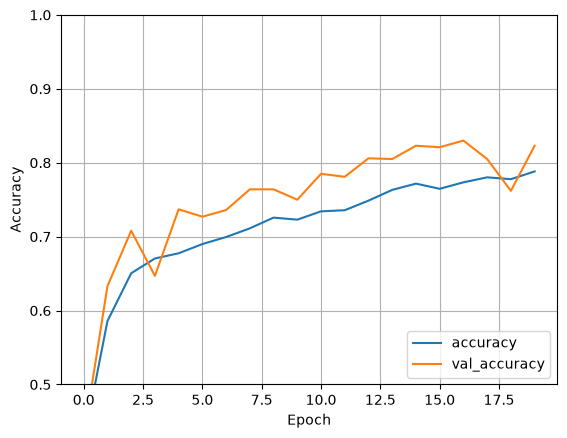

In [6]:
plt.plot(history.history['accuracy'], label='accuracy')
plt.plot(history.history['val_accuracy'], label = 'val_accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.ylim([0.5, 1])
plt.legend(loc='lower right')
plt.grid(visible=True)

In [7]:
test_acc

0.7590000033378601

In [ ]:
plt.imshow(test_images[0])

NameError: name 'test_images' is not defined

In [ ]:
test_labels

<tf.Tensor: shape=(32,), dtype=int32, numpy=
array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0], dtype=int32)>

In [ ]:
test.scan

<bound method DatasetV2.scan of <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 150, 150, 1), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))>>

In [ ]:
import pandas as pd
m = pd.read_csv("../DATA/manifest.csv")
train_h = set(m[m.split == "train"].sha256)
test_h = set(m[m.split == "test"].sha256)
print(len(train_h & test_h))   # malo by byť 0

7


In [ ]:
import tensorflow as tf

def corr2d(X: tf.TensorArray, K: tf.TensorArray) -> tf.TensorArray:
    h, w = K.shape
    Y = tf.Variable(
        tf.zeros((X.shape[0] - h + 1,
                  X.shape[1] - w + 1))
    )
    for i in range(Y.shape[0]):
        for j in range(Y.shape[1]):
            Y[i, j].assign(
                tf.reduce_sum(X[i:i + h, j:j + w] * K)
            )
    return Y

In [ ]:
X = tf.constant([
    [0, 1, 2],
    [3, 4, 5],
    [6, 7, 8]
], dtype=tf.float32)
K = tf.constant([
    [0, 1],
    [2, 3]
], dtype=tf.float32)
Y = corr2d(X, K)
print(Y)

<tf.Variable 'Variable:0' shape=(2, 2) dtype=float32, numpy=
array([[19., 25.],
       [37., 43.]], dtype=float32)>
